# Linear Regression

### Setup

In [25]:
import pymc as pm
import arviz as az
import numpy as np
import scipy
import scipy.stats as stats
from scipy.optimize import minimize
import pandas as pd
import matplotlib.pyplot as plt
import numdifftools as nd

### Read Data

In [20]:
data = pd.read_csv("Howell1.csv", delimiter=";")
heights = data['height'].tolist()

## Prior Simulation

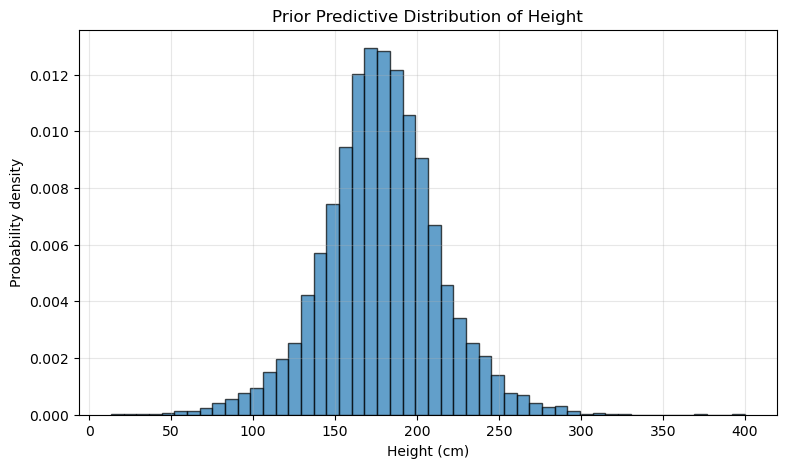

In [21]:
# Prior specification
mu = stats.norm(loc=178, scale=20)
sigma = stats.uniform(loc=0, scale=50)

# Prior simulation
mu_samples = mu.rvs(size=10000)
sigma_samples = sigma.rvs(size=10000)

h_samples = stats.norm.rvs(loc=mu_samples, scale=sigma_samples)

# Plotting priors simulation

plt.figure(figsize=(9, 5))

plt.hist(h_samples, bins=50, density=True, alpha=0.7, edgecolor="black")

plt.xlabel("Height (cm)")
plt.ylabel("Probability density")
plt.title("Prior Predictive Distribution of Height")
plt.grid(alpha=0.3)
plt.show()

## Quadratic Approximation

In [22]:
def log_posterior(theta, heights=heights):
    mu, sigma = theta

    # Log-likelihood
    log_likelihood = np.sum(stats.norm.logpdf(heights, loc=mu, scale=sigma))

    # Log-priors
    log_prior_mu = stats.norm.logpdf(mu, loc=178, scale=20)
    log_prior_sigma = stats.uniform.logpdf(sigma, loc=0, scale=50)

    # Log-posterior (up to an additive constant)
    return log_likelihood + log_prior_mu + log_prior_sigma

#### Finding MAP

In [27]:
result = minimize(
    fun=lambda theta: -log_posterior(theta, heights),
    x0=[178, 20],
    bounds=[(None, None), (1e-6, 50)],
    method="L-BFGS-B",
)
theta_map = result.x

print(result.success)
print(result.x)

True
[138.40197858  27.57739029]


In [28]:
# Hessian of the negative log-posterior
H = nd.Hessian(lambda theta: -log_posterior(theta, heights))(theta_map)

print("MAP:", theta_map)
print("Hessian:", H)

MAP: [138.40197858  27.57739029]
Hessian: [[ 0.71780715 -0.00717877]
 [-0.00717877  1.43061789]]


#### Covariance as Inverse of Hessian

In [29]:
covariance = np.linalg.inv(H)

print("Covariance matrix:")
print(covariance)

Covariance matrix:
[[1.39320176 0.00699101]
 [0.00699101 0.69903375]]


In [30]:
approx_posterior = stats.multivariate_normal(mean=theta_map, cov=covariance)

## Posterior Simulation

In [33]:
posterior_draws = approx_posterior.rvs(size=10000)

mu_draws = posterior_draws[:, 0]
sigma_draws = posterior_draws[:, 1]

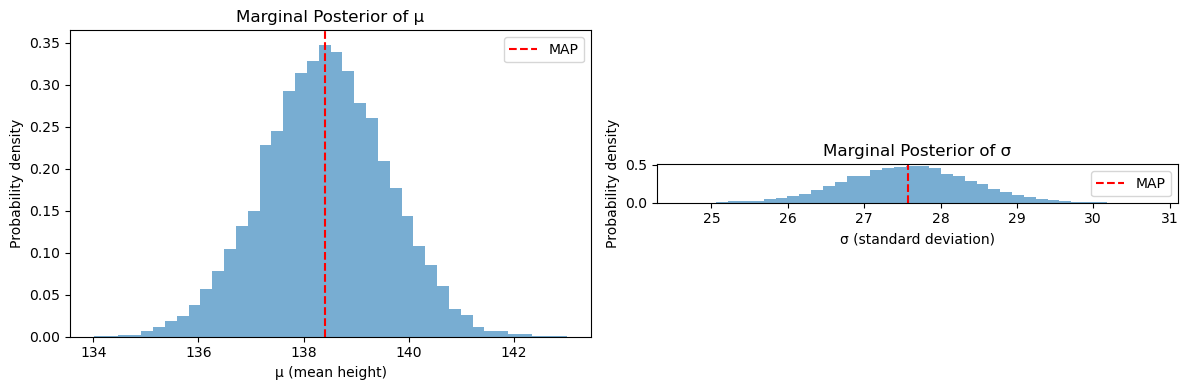

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Posterior of mu
axes[0].hist(mu_draws, bins=40, density=True, alpha=0.6)
axes[0].axvline(theta_map[0], color="red", linestyle="--", label="MAP")
axes[0].set_xlabel("μ (mean height)")
axes[0].set_ylabel("Probability density")
axes[0].set_title("Marginal Posterior of μ")
axes[0].legend()

# Posterior of sigma
axes[1].hist(sigma_draws, bins=40, density=True, alpha=0.6)
axes[1].axvline(theta_map[1], color="red", linestyle="--", label="MAP")
axes[1].set_xlabel("σ (standard deviation)")
axes[1].set_ylabel("Probability density")
axes[1].set_title("Marginal Posterior of σ")
ax = plt.gca()
ax.set_aspect("equal", adjustable="box")
axes[1].legend()

plt.tight_layout()
plt.show()

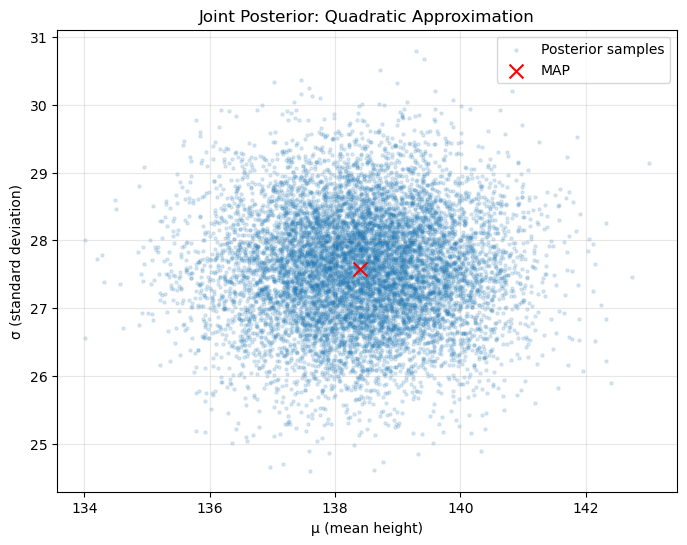

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    mu_draws,
    sigma_draws,
    alpha=0.15,
    s=5,
    label="Posterior samples"
)

plt.scatter(
    theta_map[0],
    theta_map[1],
    color="red",
    marker="x",
    s=100,
    label="MAP"
)

plt.xlabel("μ (mean height)")
plt.ylabel("σ (standard deviation)")
plt.title("Joint Posterior: Quadratic Approximation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

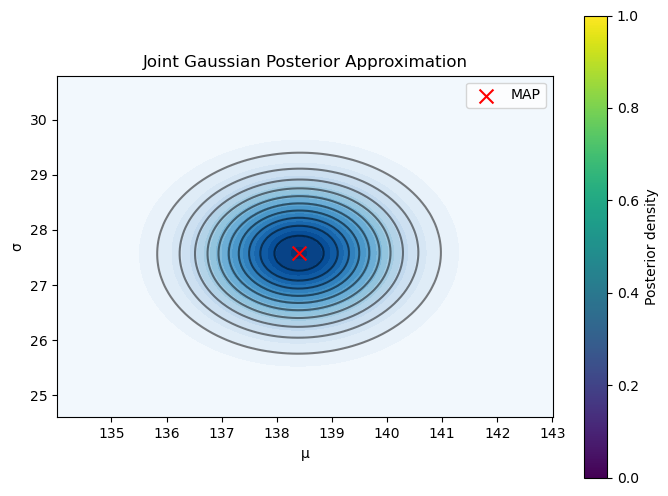

In [40]:
mu_grid = np.linspace(mu_draws.min(), mu_draws.max(), 100)
sigma_grid = np.linspace(sigma_draws.min(), sigma_draws.max(), 100)

MU, SIGMA = np.meshgrid(mu_grid, sigma_grid)

positions = np.dstack((MU, SIGMA))
density = approx_posterior.pdf(positions)

plt.figure(figsize=(8, 6))

plt.contourf(MU, SIGMA, density, levels=20, cmap="Blues")
plt.contour(MU, SIGMA, density, levels=10, colors="black", alpha=0.5)

plt.scatter(
    theta_map[0],
    theta_map[1],
    color="red",
    marker="x",
    s=100,
    label="MAP"
)

plt.xlabel("μ")
plt.ylabel("σ")
ax = plt.gca()
ax.set_aspect("equal", adjustable="box")
plt.title("Joint Gaussian Posterior Approximation")
plt.colorbar(label="Posterior density")
plt.legend()
plt.show()